# 🌊 DO EARLY-WARNING SYSTEM: END-TO-END MULTIMODAL ML + DEEP LEARNING TRAINING
## Data Audit, Preprocessing, GPU Training of 5 Models, Stacking Ensemble & Blind Evaluation
**Forecasting low dissolved oxygen 24 hours ahead in 30 US rivers** · 21CSC305P Machine Learning · SRM IST Ramapuram

---

### Executive Technical Abstract
Dissolved oxygen (DO) below **5 mg/L** stresses fish and can kill them. By the time a sensor reads it, the damage is done.
This notebook trains, from real data, the complete system that forecasts DO and warns **before** the river turns dangerous.

#### Key System Highlights
1. **Multimodal data** — USGS water-quality sensors + ERA5 weather + CAMS air quality, **211 engineered features** per hour.
2. **Leakage-free chronological split** — train on **2023**, tune on **2024**, test blind on **2025**; scalers and imputers
   are fitted on 2023 only.
3. **Five learners from two families** — Random Forest, XGBoost, LightGBM (machine learning) and BiLSTM, CNN-LSTM
   (multi-task deep learning on the GPU with mixed precision).
4. **Stacking meta-learner** fitted on the 2024 forecasts, plus an **early-warning rule P(Low) ≥ τ** under a 2 % false-alarm budget.
5. **Blind evaluation** on the 2025 test year: regression, classification and early-warning metrics, then a live single-hour prediction.

> ⏱️ **Runs in a few minutes.** This notebook trains on the **demo pack** — the project's real processed data for all
> 30 stations, thinned to **every 4th hour** (≈ 64,000 rows per year). With `FAST_DEMO = True` the Random Forest uses 100
> trees instead of 300 and the networks stop after at most 10 epochs; every other hyperparameter is the **frozen** one. Section 10 places these numbers next to the full-dataset run trained on the RTX 3050 laptop.

## 0. Load the Demo Data Pack
Put **`do_demo_pack.npz`** (about 77 MB, made by `python make_demo_pack.py`) in the top folder of your Google Drive — or run the
cell and upload it when asked. On your own computer it is read from the project folder.

In [1]:
# @title 📦 Step 0: Locate and load do_demo_pack.npz
import os, sys, numpy as np
PACK = None
for p in ["do_demo_pack.npz", "../do_demo_pack.npz", "/content/do_demo_pack.npz", "/content/drive/MyDrive/do_demo_pack.npz"]:
    if os.path.exists(p):
        PACK = p; break
if PACK is None and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists("/content/drive/MyDrive/do_demo_pack.npz"):
        PACK = "/content/drive/MyDrive/do_demo_pack.npz"
    else:
        from google.colab import files
        print("do_demo_pack.npz is not in My Drive - please upload it now:")
        files.upload(); PACK = "do_demo_pack.npz"
assert PACK and os.path.exists(PACK), "do_demo_pack.npz not found"
D = dict(np.load(PACK))
FAST_DEMO = True   # True: 100 RF trees, <= 10 epochs (about 5 min on a Colab T4) | False: frozen 300 trees, <= 15 epochs
print(f"[OK] loaded {PACK} ({os.path.getsize(PACK) / 1e6:.0f} MB): {len(D['stations'])} stations, "
      f"{len(D['feature_names'])} features, {D['channels'].shape[0]:,} station-hours of raw history")

[OK] loaded ../do_demo_pack.npz (77 MB): 30 stations, 211 features, 789,120 station-hours of raw history


## 1. Environment Verification & GPU Acceleration Setup

In [2]:
# @title 🖥️ Environment & GPU check
import time, random, warnings, json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
import sklearn, xgboost as xgb, lightgbm as lgb
import torch, torch.nn as nn
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TIMES = {}

print("=" * 80)
print("DO EARLY-WARNING SYSTEM: TRAINING RUNTIME ENVIRONMENT")
print(f"Python           : {sys.version.split()[0]}")
print(f"scikit-learn     : {sklearn.__version__} | XGBoost {xgb.__version__} | LightGBM {lgb.__version__}")
print(f"PyTorch          : {torch.__version__}")
print(f"Hardware Compute : {device}")
if device.type == "cuda":
    print(f"GPU Device Name  : {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM       : {torch.cuda.get_device_properties(0).total_memory / 1024**2:,.0f} MB")
else:
    print("No GPU found - deep models train on the CPU (slower). In Colab: Runtime -> Change runtime type -> T4 GPU")
print(f"CPU cores        : {os.cpu_count()}")
print("=" * 80)

DO EARLY-WARNING SYSTEM: TRAINING RUNTIME ENVIRONMENT
Python           : 3.13.16
scikit-learn     : 1.9.1 | XGBoost 3.4.1 | LightGBM 4.7.0
PyTorch          : 2.14.1+cu130
Hardware Compute : cpu
No GPU found - deep models train on the CPU (slower). In Colab: Runtime -> Change runtime type -> T4 GPU
CPU cores        : 2


## 2. Dataset Audit & Leakage Verification

### Why a chronological split is mandatory for forecasting
Neighbouring hours are almost identical. A random split puts 10:00 in training and 11:00 in testing, so the model
"predicts" by memory and scores look far better than they will in real use. We therefore split **by calendar year**
and check that no test hour lies inside the training or validation period.

In [3]:
# @title 🔍 Partition audit
FEATURES = list(D["feature_names"]); TARGETS = list(D["target_names"]); STATIONS = list(D["stations"])
H_ALL = [6, 12, 24, 48]; H = 24                          # this notebook reports the 24 h horizon
CLASSES = ["Low", "Medium", "Good"]; LOW, GOOD = 5.0, 7.0
col = {t: i for i, t in enumerate(TARGETS)}

def to_class(do):
    out = np.full(do.shape, np.nan); out[do < LOW] = 0; out[(do >= LOW) & (do <= GOOD)] = 1; out[do > GOOD] = 2
    return out

SPLITS = {}
for s, year in [("train", 2023), ("val", 2024), ("test", 2025)]:
    SPLITS[s] = {"X": pd.DataFrame(D[f"{s}_X"], columns=FEATURES), "y": D[f"{s}_y"], "do_now": D[f"{s}_do_now"].astype("float64"),
                 "station": D[f"{s}_station"].astype(int), "pos": D[f"{s}_pos"].astype(int), "time": D[f"{s}_time"]}
    SPLITS[s]["class_now"] = to_class(SPLITS[s]["do_now"])

rows = []
for s, d in SPLITS.items():
    c = d["y"][:, col[f"y_cls_{H}"]]
    rows.append({"split": s, "rows": len(d["X"]), "stations": len(np.unique(d["station"])),
                 "from": str(d["time"].min())[:10], "to": str(d["time"].max())[:10],
                 "% Low": np.nanmean(c == 0) * 100, "% Medium": np.nanmean(c == 1) * 100, "% Good": np.nanmean(c == 2) * 100})
display(pd.DataFrame(rows).set_index("split").style.format("{:.1f}", subset=["% Low", "% Medium", "% Good"]))

ok_order = SPLITS["train"]["time"].max() < SPLITS["val"]["time"].min() and SPLITS["val"]["time"].max() < SPLITS["test"]["time"].min()
print("=" * 80)
print("LEAKAGE VERIFICATION:")
print(f"  last training hour   : {SPLITS['train']['time'].max()}")
print(f"  first validation hour: {SPLITS['val']['time'].min()}   last: {SPLITS['val']['time'].max()}")
print(f"  first test hour      : {SPLITS['test']['time'].min()}")
print(f"  chronological order  : {'PASSED [OK]' if ok_order else 'FAILED'}  (train < validation < test, no overlap)")
print(f"  features use only data at or before time t; targets are DO at t+{H} h")
print("=" * 80)

,rows,stations,from,to,% Low,% Medium,% Good
split,,,,,,,
train,63818,30,2023-01-04,2023-12-29,19.1,27.4,52.8
val,63408,30,2024-01-01,2024-12-29,20.3,24.3,54.7
test,63497,30,2025-01-01,2025-12-31,19.4,24.9,54.8


LEAKAGE VERIFICATION:
  last training hour   : 2023-12-29T23
  first validation hour: 2024-01-01T00   last: 2024-12-29T23
  first test hour      : 2025-01-01T00
  chronological order  : PASSED [OK]  (train < validation < test, no overlap)
  features use only data at or before time t; targets are DO at t+24 h


## 3. Preprocessing & Class-Imbalance Handling

| Step | What | Fitted on |
|---|---|---|
| Missing values (trees) | XGBoost / LightGBM learn a direction for NaN; Random Forest uses a **median imputer** | 2023 only |
| Missing values (deep) | raw series forward-filled **within a station, never backwards**; remaining gaps = training median | 2023 only |
| Scaling (deep) | `StandardScaler` on the 33 hourly channels and on the 211 features | 2023 only |
| Class imbalance | weights $w_c = \dfrac{n}{K \cdot n_c}$ so the minority **Low** class counts as much as the others | 2023 only |

The 33 hourly channels: 6 water variables + their 6 "was missing" flags, DO saturation, 8 weather, 8 air-quality and
4 time encodings (hour and day-of-year as sin/cos).

In [4]:
# @title ⚙️ Targets, class weights and evaluation helpers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, roc_curve, auc as sk_auc)

def xy(split, task):
    d = SPLITS[split]; y = d["y"][:, col[f"y_{'reg' if task == 'regression' else 'cls'}_{H}"]].astype("float64")
    ok = ~np.isnan(y)
    return d["X"][ok], (y[ok] if task == "regression" else y[ok].astype(int))

def balanced_weights(y):
    cls, cnt = np.unique(y, return_counts=True); w = {c: len(y) / (len(cls) * n) for c, n in zip(cls, cnt)}
    return np.array([w[v] for v in y])

def early_warning(class_now, y_true, y_pred):
    ok = ~np.isnan(class_now) & ~np.isnan(y_true)
    now, t, p = class_now[ok], y_true[ok], y_pred[ok]
    onset = (now != 0) & (t == 0); safe = (now != 0) & (t != 0)
    return {"onset_recall": (onset & (p == 0)).sum() / max(onset.sum(), 1), "false_alarm": (safe & (p == 0)).sum() / max(safe.sum(), 1)}

def evaluate(split, reg, proba, pred=None):
    d = SPLITS[split]; yr = d["y"][:, col[f"y_reg_{H}"]].astype("float64"); yc = d["y"][:, col[f"y_cls_{H}"]].astype("float64")
    ok_r = ~np.isnan(yr) & ~np.isnan(reg); e = reg[ok_r] - yr[ok_r]
    pers = np.sqrt(np.mean((d["do_now"][ok_r] - yr[ok_r]) ** 2))
    pred = proba.argmax(1) if pred is None else pred
    ok = ~np.isnan(yc) & ~np.isnan(proba).any(1)
    t, p = yc[ok].astype(int), pred[ok].astype(int)
    out = {"R2": 1 - np.sum(e ** 2) / np.sum((yr[ok_r] - yr[ok_r].mean()) ** 2), "RMSE": np.sqrt(np.mean(e ** 2)),
           "MAE": np.mean(np.abs(e)), "skill": 1 - np.sqrt(np.mean(e ** 2)) / pers,
           "accuracy": accuracy_score(t, p), "balanced_acc": balanced_accuracy_score(t, p),
           "macro_F1": f1_score(t, p, average="macro"), "ROC_AUC": roc_auc_score(t, proba[ok], multi_class="ovr", average="macro"),
           "Low_recall": recall_score(t, p, labels=[0], average="macro"), "Low_precision": precision_score(t, p, labels=[0], average="macro", zero_division=0)}
    out.update(early_warning(d["class_now"], yc, pred))
    return out

PRED = {}          # PRED[model] = {"val_reg", "val_proba", "test_reg", "test_proba"}
_, ytr = xy("train", "classification")
print("Class counts in 2023 (24 h target):", dict(zip(CLASSES, np.bincount(ytr))))
print("Balanced class weights            :", {CLASSES[c]: round(len(ytr) / (3 * n), 3) for c, n in enumerate(np.bincount(ytr))})

Class counts in 2023 (24 h target): {'Low': np.int64(12173), 'Medium': np.int64(17497), 'Good': np.int64(33693)}
Balanced class weights            : {'Low': np.float64(1.735), 'Medium': np.float64(1.207), 'Good': np.float64(0.627)}


## 4. Machine-Learning Model 1 — Random Forest

$$\hat y(x) = \frac{1}{T}\sum_{t=1}^{T} f_t(x) \qquad \text{(bagging: each tree sees a bootstrap half of the rows and 30 \% of the features per split)}$$

Frozen settings: 300 trees (100 with `FAST_DEMO`) · `min_samples_leaf=20` · `max_features=0.3` · `max_samples=0.5` · class weights *balanced_subsample* · median imputer.

In [5]:
# @title 🌲 Train Random Forest (regression + classification)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

RF = dict(n_estimators=100 if FAST_DEMO else 300, min_samples_leaf=20, max_features=0.3, max_samples=0.5, n_jobs=-1, random_state=SEED)
out, t0 = {}, time.perf_counter()
for task in ["regression", "classification"]:
    X, y = xy("train", task)
    est = RandomForestRegressor(**RF) if task == "regression" else RandomForestClassifier(class_weight="balanced_subsample", **RF)
    t1 = time.perf_counter(); model = Pipeline([("impute", SimpleImputer(strategy="median")), ("model", est)]).fit(X, y)
    print(f"  {task:<14} trained on {len(X):,} rows in {time.perf_counter() - t1:5.1f}s")
    for s in ["val", "test"]:
        Xs = SPLITS[s]["X"]
        out[f"{s}_{'reg' if task == 'regression' else 'proba'}"] = model.predict(Xs) if task == "regression" else model.predict_proba(Xs)
    if task == "regression":
        RF_IMP = pd.Series(model.named_steps["model"].feature_importances_, index=FEATURES)
PRED["random_forest"] = out; TIMES["Random Forest"] = time.perf_counter() - t0
display(pd.DataFrame({s: evaluate(s, out[f"{s}_reg"], out[f"{s}_proba"]) for s in ["val", "test"]}).T.style.format("{:.4f}"))

  regression     trained on 63,363 rows in  55.0s


  classification trained on 63,363 rows in  66.4s


,R2,RMSE,MAE,skill,accuracy,balanced_acc,macro_F1,ROC_AUC,Low_recall,Low_precision,onset_recall,false_alarm
val,0.9474,0.6726,0.4162,0.0844,0.9065,0.8955,0.8903,0.9806,0.9118,0.8987,0.2489,0.0044
test,0.9448,0.7102,0.4309,0.0559,0.9058,0.8942,0.8892,0.9802,0.9022,0.8881,0.2220,0.0041


## 5. Machine-Learning Model 2 — XGBoost

Second-order gradient boosting: each new tree minimises
$\;\mathcal{L}^{(t)} \approx \sum_i \big[g_i f_t(x_i) + \tfrac12 h_i f_t(x_i)^2\big] + \gamma T + \tfrac12\lambda\lVert w\rVert^2$,
with $g_i, h_i$ the first and second derivatives of the loss.
Frozen settings: learning rate 0.05 · depth 8 · subsample 0.8 · colsample 0.7 · histogram splits (GPU when available) ·
**early stopping on 2024** (50 rounds patience, max 2,000 trees) · balanced sample weights.

In [6]:
# @title 🚀 Train XGBoost (GPU if available)
XG = dict(tree_method="hist", learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.7,
          n_estimators=2000, early_stopping_rounds=50, random_state=SEED, n_jobs=-1)
if device.type == "cuda":
    XG["device"] = "cuda"
out, CURVES, t0 = {}, {}, time.perf_counter()
for task in ["regression", "classification"]:
    X, y = xy("train", task); Xv, yv = xy("val", task)
    if task == "regression":
        model = xgb.XGBRegressor(eval_metric="rmse", **XG); w = None
    else:
        model = xgb.XGBClassifier(objective="multi:softprob", num_class=3, eval_metric="mlogloss", **XG); w = balanced_weights(y)
    t1 = time.perf_counter(); model.fit(X, y, sample_weight=w, eval_set=[(X, y), (Xv, yv)], verbose=False)
    CURVES[("XGBoost", task)] = model.evals_result()
    print(f"  {task:<14} best iteration {model.best_iteration:>4} | {time.perf_counter() - t1:5.1f}s")
    for s in ["val", "test"]:
        Xs = SPLITS[s]["X"]
        out[f"{s}_{'reg' if task == 'regression' else 'proba'}"] = model.predict(Xs) if task == "regression" else model.predict_proba(Xs)
PRED["xgboost"] = out; TIMES["XGBoost"] = time.perf_counter() - t0
display(pd.DataFrame({s: evaluate(s, out[f"{s}_reg"], out[f"{s}_proba"]) for s in ["val", "test"]}).T.style.format("{:.4f}"))

  regression     best iteration  226 |  77.8s


  classification best iteration  183 | 142.8s


,R2,RMSE,MAE,skill,accuracy,balanced_acc,macro_F1,ROC_AUC,Low_recall,Low_precision,onset_recall,false_alarm
val,0.9483,0.6670,0.4140,0.0920,0.9093,0.8986,0.8936,0.9816,0.9102,0.9044,0.3177,0.0063
test,0.9410,0.7339,0.4427,0.0244,0.9070,0.8949,0.8905,0.9811,0.8976,0.8939,0.2637,0.0054


## 6. Machine-Learning Model 3 — LightGBM

Leaf-wise boosting (grows the leaf with the largest loss reduction). Frozen settings: learning rate 0.05 · 63 leaves ·
≥ 50 rows per leaf · 70 % feature / 80 % row bagging · `station_id` as a true **categorical** feature ·
`class_weight="balanced"` · early stopping on 2024.

In [7]:
# @title 💡 Train LightGBM
LG = dict(learning_rate=0.05, num_leaves=63, min_child_samples=50, feature_fraction=0.7, bagging_fraction=0.8,
          bagging_freq=1, n_estimators=2000, random_state=SEED, n_jobs=-1, verbose=-1)
CATS = sorted(np.unique(SPLITS["train"]["X"]["station_id"].astype(int)))
def as_lgb(X):
    X = X.copy(); X["station_id"] = pd.Categorical(X["station_id"].astype(int), categories=CATS); return X
out, t0 = {}, time.perf_counter()
for task in ["regression", "classification"]:
    X, y = xy("train", task); Xv, yv = xy("val", task); curve = {}
    model = (lgb.LGBMRegressor(objective="regression", **LG) if task == "regression"
             else lgb.LGBMClassifier(objective="multiclass", num_class=3, class_weight="balanced", **LG))
    t1 = time.perf_counter()
    model.fit(as_lgb(X), y, eval_set=[(as_lgb(X), y), (as_lgb(Xv), yv)], eval_names=["train", "validation"],
              callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0), lgb.record_evaluation(curve)])
    CURVES[("LightGBM", task)] = curve
    print(f"  {task:<14} best iteration {model.best_iteration_:>4} | {time.perf_counter() - t1:5.1f}s")
    for s in ["val", "test"]:
        Xs = as_lgb(SPLITS[s]["X"])
        out[f"{s}_{'reg' if task == 'regression' else 'proba'}"] = model.predict(Xs) if task == "regression" else model.predict_proba(Xs)
    if task == "regression":
        LGB_IMP = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
PRED["lightgbm"] = out; TIMES["LightGBM"] = time.perf_counter() - t0
display(pd.DataFrame({s: evaluate(s, out[f"{s}_reg"], out[f"{s}_proba"]) for s in ["val", "test"]}).T.style.format("{:.4f}"))

  regression     best iteration  172 |  11.8s


  classification best iteration  169 |  29.2s


,R2,RMSE,MAE,skill,accuracy,balanced_acc,macro_F1,ROC_AUC,Low_recall,Low_precision,onset_recall,false_alarm
val,0.9500,0.6560,0.4081,0.1069,0.9074,0.8971,0.8918,0.9816,0.9103,0.9044,0.3466,0.0072
test,0.9470,0.6957,0.4268,0.0752,0.9066,0.8940,0.8901,0.9814,0.8954,0.8968,0.2888,0.0061


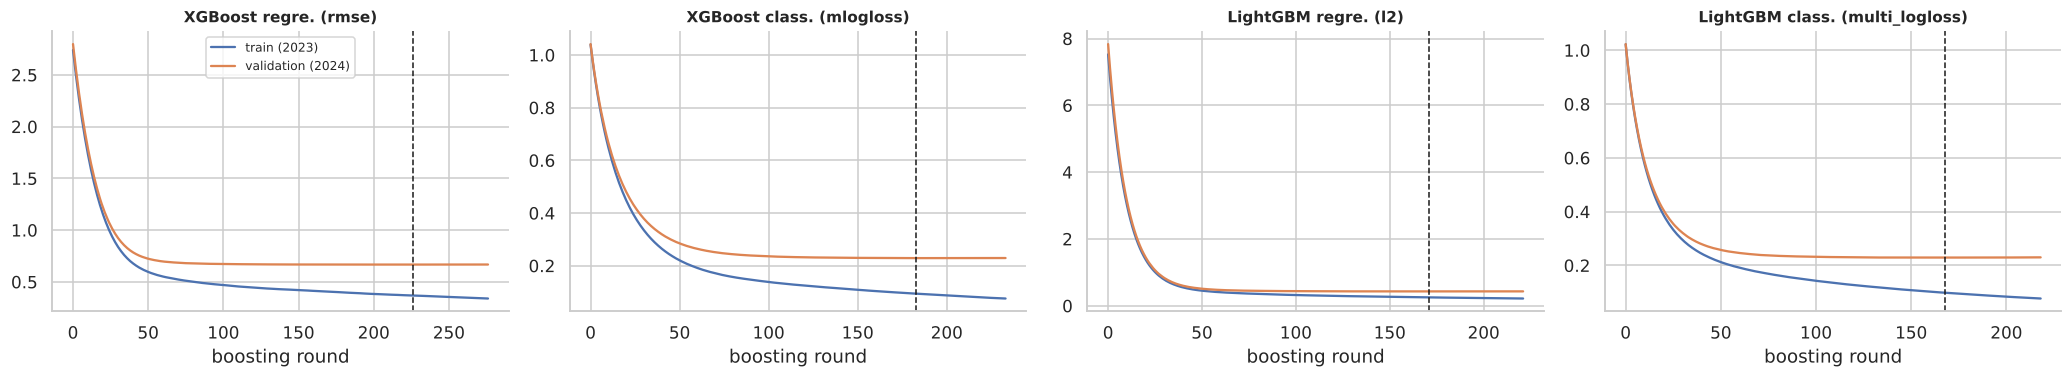

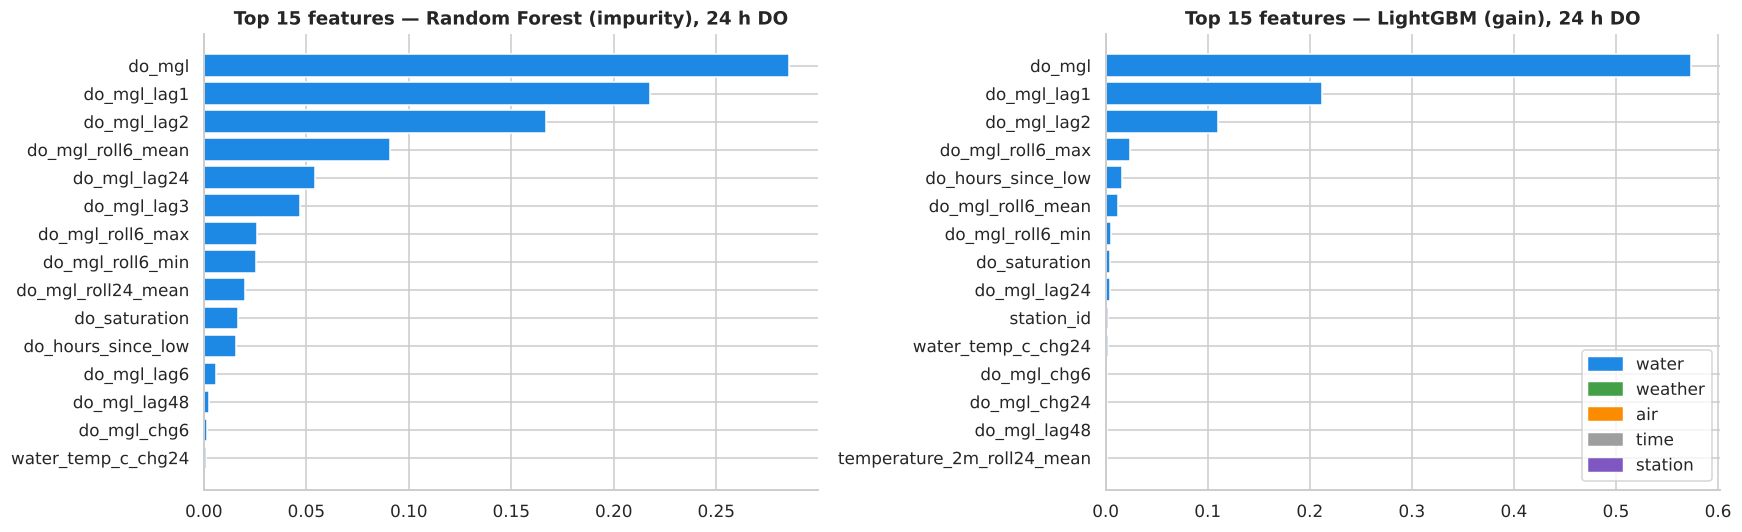

In [8]:
# @title 📉 Boosting curves (early stopping) & what the trees rely on
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (lib, task) in zip(axes, [("XGBoost", "regression"), ("XGBoost", "classification"), ("LightGBM", "regression"), ("LightGBM", "classification")]):
    ev = CURVES[(lib, task)]
    if lib == "XGBoost":
        m = list(ev["validation_0"])[0]; tr, va = ev["validation_0"][m], ev["validation_1"][m]
    else:
        m = list(ev["validation"])[0]; tr, va = ev["train"][m], ev["validation"][m]
    ax.plot(tr, label="train (2023)"); ax.plot(va, label="validation (2024)"); ax.axvline(int(np.argmin(va)), color="k", ls="--", lw=1)
    ax.set_title(f"{lib} {task[:5]}. ({m})", fontweight="bold", fontsize=10); ax.set_xlabel("boosting round")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

GROUP = {}
for f in FEATURES:
    GROUP[f] = ("station" if f.startswith("station") else "time" if f.startswith(("hour", "doy", "month", "dow")) else
                "air" if any(k in f for k in ["pm10", "pm2_5", "carbon", "nitrogen", "sulphur", "ozone", "aerosol", "dust"]) else
                "weather" if any(k in f for k in ["temperature_2m", "humidity", "precip", "pressure", "wind", "radiation", "soil", "et0", "rain"]) else "water")
COLS = {"water": "#1E88E5", "weather": "#43A047", "air": "#FB8C00", "time": "#9E9E9E", "station": "#7E57C2"}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (imp, t) in zip(axes, [(RF_IMP, "Random Forest (impurity)"), (LGB_IMP, "LightGBM (gain)")]):
    top = (imp / imp.sum()).sort_values().tail(15)
    ax.barh(top.index, top.values, color=[COLS[GROUP[f]] for f in top.index]); ax.set_title(f"Top 15 features — {t}, 24 h DO", fontweight="bold")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLS.values()], COLS.keys(), loc="lower right")
plt.tight_layout(); plt.show()

## 7. Deep-Learning Models 4 & 5 — BiLSTM and CNN-LSTM (GPU)

**Input** for a forecast at time *t*: the last **72 hours × 33 channels** + a learned **station embedding** (8 numbers per river)
+ a **hybrid branch** with the 211 engineered features at *t*. **Output** (multi-task, one pass): DO change at 6/12/24/48 h
and 4 × 3 class logits. The regression head predicts the **change**: $\hat y = DO(t) + \text{out}\cdot\sigma_{DO}$.

**Loss** — masked MSE + class-weighted cross-entropy, averaged over horizons (missing targets contribute nothing):
$$\mathcal{L} = \frac{1}{|\mathcal{H}|}\sum_{h}\frac{\sum_i m_{ih}(\hat\delta_{ih}-\delta_{ih})^2}{\sum_i m_{ih}} \;+\; \frac{1}{|\mathcal{H}|}\sum_h \Big(-\frac{\sum_i w_{y_{ih}} \log p_{ih}(y_{ih})}{\sum_i w_{y_{ih}}}\Big)$$

**Optimisation** — AdamW (lr 5·10⁻⁴, weight decay 10⁻⁴) · dropout 0.3 · ReduceLROnPlateau (×0.5, patience 2) · gradient
clipping 1.0 · automatic mixed precision on the GPU · **early stopping on the 2024 validation loss** (patience 4).

In [9]:
# @title 🧱 Build 72-hour windows (scalers fitted on 2023 only)
from sklearn.preprocessing import StandardScaler
SEQ, NCH = 72, D["channels"].shape[1]
off, lens = D["offsets"], D["lengths"]
raw = D["channels"].astype("float32").copy()
start = pd.to_datetime(D["start"]); in2023 = np.zeros(len(raw), bool)
for i in range(len(STATIONS)):
    t = start[i] + pd.to_timedelta(np.arange(lens[i]), unit="h"); in2023[off[i]:off[i] + lens[i]] = (t.year == 2023)
med = np.nanmedian(raw[in2023], axis=0); raw = np.where(np.isnan(raw), med, raw)
ch_scaler = StandardScaler().fit(raw[in2023]); CH = ch_scaler.transform(raw).astype("float32")
do_scale = float(ch_scaler.scale_[list(D["channel_names"]).index("do_mgl")])

f_med = SPLITS["train"]["X"].median()
f_scaler = StandardScaler().fit(SPLITS["train"]["X"].fillna(f_med).fillna(0))
for s, d in SPLITS.items():
    d["F"] = np.nan_to_num(f_scaler.transform(d["X"].fillna(f_med).fillna(0))).astype("float32")
    yreg = np.stack([d["y"][:, col[f"y_reg_{h}"]] for h in H_ALL], 1)
    d["reg_t"] = ((yreg - d["do_now"][:, None]) / do_scale).astype("float32")          # scaled DO CHANGE, NaN if unknown
    yc = np.stack([d["y"][:, col[f"y_cls_{h}"]] for h in H_ALL], 1)
    d["cls_t"] = np.where(np.isnan(yc), -1, yc).astype("int64")                         # -1 = ignore
    d["start_idx"] = (off[d["station"]] + d["pos"] - SEQ + 1).astype("int64")

def batch(split, ids):
    d = SPLITS[split]; idx = d["start_idx"][ids][:, None] + np.arange(SEQ)[None, :]
    return (torch.from_numpy(CH[idx]), torch.from_numpy(d["station"][ids].astype("int64")), torch.from_numpy(d["F"][ids]),
            torch.from_numpy(d["reg_t"][ids]), torch.from_numpy(d["cls_t"][ids]))

x, st, f, r, c = batch("train", np.arange(4))
print(f"[OK] windows ready: one sample = {tuple(x.shape[1:])} hourly sequence + {f.shape[1]} features + station id")
print(f"     train {len(SPLITS['train']['X']):,} | val {len(SPLITS['val']['X']):,} | test {len(SPLITS['test']['X']):,} windows")

[OK] windows ready: one sample = (72, 33) hourly sequence + 211 features + station id
     train 63,818 | val 63,408 | test 63,497 windows


In [10]:
# @title 🧠 Network architectures + multi-task loss
N_ST, N_H, N_CLS = len(STATIONS), len(H_ALL), 3

class Heads(nn.Module):
    def __init__(self, width, dense=64, p=0.3):
        super().__init__(); self.body = nn.Sequential(nn.Linear(width, dense), nn.ReLU(), nn.Dropout(p))
        self.reg, self.cls = nn.Linear(dense, N_H), nn.Linear(dense, N_H * N_CLS)
    def forward(self, z):
        z = self.body(z); return self.reg(z), self.cls(z).view(-1, N_H, N_CLS)

class BiLSTM(nn.Module):
    def __init__(self, hidden=32, p=0.3):
        super().__init__(); self.emb = nn.Embedding(N_ST, 8)
        self.lstm = nn.LSTM(NCH, hidden, num_layers=2, bidirectional=True, dropout=p, batch_first=True)
        self.feat = nn.Sequential(nn.Linear(len(FEATURES), 64), nn.ReLU(), nn.Dropout(p)); self.heads = Heads(2 * hidden + 8 + 64, p=p)
    def forward(self, x, s, f):
        _, (h, _) = self.lstm(x); return self.heads(torch.cat([h[-2], h[-1], self.emb(s), self.feat(f)], 1))

class CNNLSTM(nn.Module):
    def __init__(self, hidden=32, p=0.3):
        super().__init__(); self.emb = nn.Embedding(N_ST, 8)
        self.conv = nn.Sequential(nn.Conv1d(NCH, 32, 3, padding=1), nn.ReLU(), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2))
        self.lstm = nn.LSTM(64, hidden, batch_first=True)
        self.feat = nn.Sequential(nn.Linear(len(FEATURES), 64), nn.ReLU(), nn.Dropout(p)); self.heads = Heads(hidden + 8 + 64, p=p)
    def forward(self, x, s, f):
        z = self.conv(x.transpose(1, 2)); _, (h, _) = self.lstm(z.transpose(1, 2))
        return self.heads(torch.cat([h[-1], self.emb(s), self.feat(f)], 1))

cls_tr = SPLITS["train"]["cls_t"]
CW = torch.tensor([[len(c[c >= 0]) / (3 * max((c == k).sum(), 1)) for k in range(3)] for c in cls_tr.T], dtype=torch.float32, device=device)

def multitask_loss(reg_out, cls_out, reg_t, cls_t):
    m = ~torch.isnan(reg_t)
    per_h = (((reg_out - torch.nan_to_num(reg_t)) ** 2) * m).sum(0) / m.sum(0).clamp(min=1)
    reg_loss = per_h[m.any(0)].mean()
    ce = [nn.functional.cross_entropy(cls_out[cls_t[:, j] >= 0, j], cls_t[cls_t[:, j] >= 0, j], weight=CW[j])
          for j in range(N_H) if (cls_t[:, j] >= 0).any()]
    return reg_loss + torch.stack(ce).mean()

for k in [BiLSTM, CNNLSTM]:
    print(f"{k.__name__:<8}: {sum(p.numel() for p in k().parameters()):,} trainable parameters")
print(BiLSTM())

BiLSTM  : 65,856 trainable parameters
CNNLSTM : 43,520 trainable parameters
BiLSTM(
  (emb): Embedding(30, 8)
  (lstm): LSTM(33, 32, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (feat): Sequential(
    (0): Linear(in_features=211, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (heads): Heads(
    (body): Sequential(
      (0): Linear(in_features=136, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.3, inplace=False)
    )
    (reg): Linear(in_features=64, out_features=4, bias=True)
    (cls): Linear(in_features=64, out_features=12, bias=True)
  )
)



=== BILSTM (65,856 params) on cpu ===


  epoch  1 | train loss 0.8737 | val loss 0.4875 | val RMSE 24 h 0.7194 | 32.7s


  epoch  2 | train loss 0.5117 | val loss 0.4089 | val RMSE 24 h 0.7126 | 34.5s


  epoch  3 | train loss 0.4470 | val loss 0.3885 | val RMSE 24 h 0.7091 | 32.8s


  epoch  4 | train loss 0.4172 | val loss 0.3765 | val RMSE 24 h 0.7025 | 33.9s


...

  epoch  6 | train loss 0.3968 | val loss 0.3642 | val RMSE 24 h 0.6916 | 10.2s


  epoch  7 | train loss 0.3863 | val loss 0.3539 | val RMSE 24 h 0.6880 |  9.8s


  epoch  8 | train loss 0.3810 | val loss 0.3495 | val RMSE 24 h 0.6857 |  9.8s


  epoch  9 | train loss 0.3722 | val loss 0.3491 | val RMSE 24 h 0.6853 |  9.5s


  epoch 10 | train loss 0.3672 | val loss 0.3466 | val RMSE 24 h 0.6821 |  8.8s
  kept epoch 10 (lowest validation loss 0.3466)


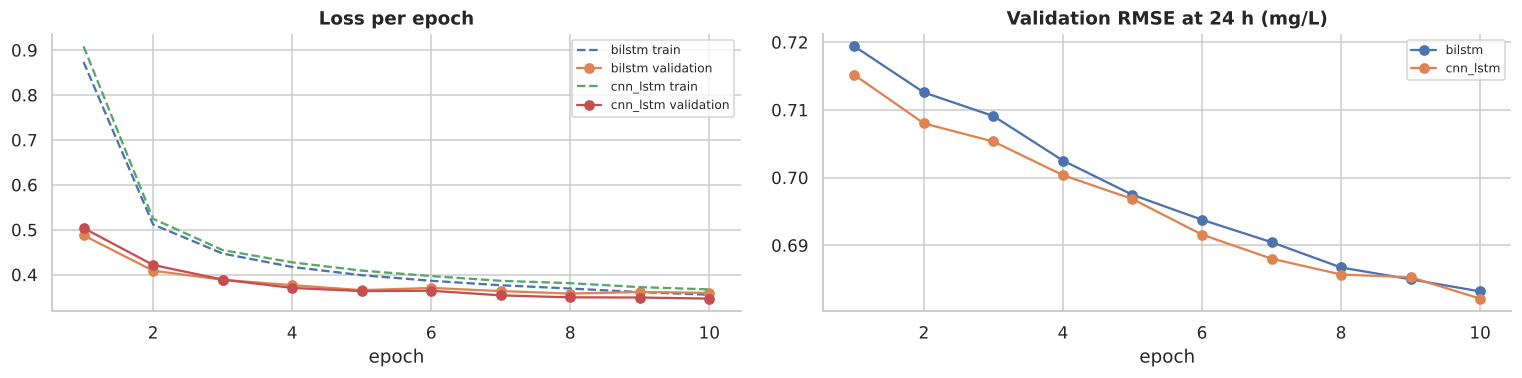

In [11]:
# @title 🔥 Train both networks (GPU, mixed precision, early stopping on 2024)
MAX_EPOCHS, PATIENCE, BS = (10 if FAST_DEMO else 15), 4, 512
use_amp = device.type == "cuda"

def run(model, split, train=False, opt=None, scaler=None):
    n = len(SPLITS[split]["X"]); order = np.random.permutation(n) if train else np.arange(n)
    model.train(train); tot, nb = 0.0, 0
    reg_p = np.empty((n, N_H), "float32"); cls_p = np.empty((n, N_H, N_CLS), "float32")
    for b in range(0, n, BS):
        ids = order[b:b + BS]; x, s, f, r, c = [t.to(device, non_blocking=True) for t in batch(split, ids)]
        with torch.set_grad_enabled(train), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            ro, co = model(x, s, f); loss = multitask_loss(ro.float(), co.float(), r, c)
        if train:
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update()
        else:
            reg_p[ids] = ro.float().detach().cpu().numpy(); cls_p[ids] = torch.softmax(co.float(), 2).detach().cpu().numpy()
        tot += loss.item(); nb += 1
    return tot / nb, reg_p, cls_p

HIST = {}
for name, Net in [("bilstm", BiLSTM), ("cnn_lstm", CNNLSTM)]:
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = Net().to(device); opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, bad, hist, t0 = (np.inf, None, 0), 0, [], time.perf_counter()
    print(f"\n=== {name.upper()} ({sum(p.numel() for p in model.parameters()):,} params) on {device} ===")
    for ep in range(1, MAX_EPOCHS + 1):
        te = time.perf_counter(); tl, _, _ = run(model, "train", True, opt, scaler); vl, rp, cp = run(model, "val")
        sched.step(vl)
        j = H_ALL.index(H); pred_do = SPLITS["val"]["do_now"] + rp[:, j] * do_scale
        yv = SPLITS["val"]["y"][:, col[f"y_reg_{H}"]]; ok = ~np.isnan(yv); rmse = np.sqrt(np.mean((pred_do[ok] - yv[ok]) ** 2))
        hist.append({"epoch": ep, "train_loss": tl, "val_loss": vl, "val_rmse_24": rmse})
        print(f"  epoch {ep:>2} | train loss {tl:.4f} | val loss {vl:.4f} | val RMSE 24 h {rmse:.4f} | {time.perf_counter() - te:4.1f}s")
        if vl < best[0] - 1e-6:
            best, bad = (vl, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  early stopping - no improvement for {PATIENCE} epochs"); break
    model.load_state_dict(best[1]); print(f"  kept epoch {best[2]} (lowest validation loss {best[0]:.4f})")
    out = {}; j = H_ALL.index(H)
    for s in ["val", "test"]:
        _, rp, cp = run(model, s); out[f"{s}_reg"] = SPLITS[s]["do_now"] + rp[:, j] * do_scale; out[f"{s}_proba"] = cp[:, j, :]
    PRED[name] = out; HIST[name] = pd.DataFrame(hist); TIMES[{"bilstm": "BiLSTM", "cnn_lstm": "CNN-LSTM"}[name]] = time.perf_counter() - t0
    globals()[f"MODEL_{name.upper()}"] = model

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for name, h in HIST.items():
    axes[0].plot(h.epoch, h.train_loss, "--", label=f"{name} train"); axes[0].plot(h.epoch, h.val_loss, "-o", label=f"{name} validation")
    axes[1].plot(h.epoch, h.val_rmse_24, "-o", label=name)
axes[0].set_title("Loss per epoch", fontweight="bold"); axes[1].set_title("Validation RMSE at 24 h (mg/L)", fontweight="bold")
for a in axes: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Stacking Ensemble + Early-Warning Rule

A meta-learner combines the five models. It is fitted on the **2024** forecasts — data none of the base models was trained
on — so it learns how far to trust each one on unseen data:

$$\hat y_{\text{DO}} = \beta_0 + \sum_{k=1}^{5}\beta_k\,\hat y_k \;\;(\text{Ridge}) \qquad
P(\text{class}) = \operatorname{softmax}\big(W\,[p_{1,L},p_{1,M},p_{1,G},\dots,p_{5,G}] + b\big) \;\;(\text{logistic, balanced})$$

**Warning rule:** issue a Low warning whenever $P(\text{Low}) \ge \tau$. τ is chosen on 2024 as the value catching the most
onsets with a false-alarm rate ≤ 1.8 % (the 2 % promise minus a safety margin), then frozen for 2025.

In [12]:
# @title ⚖️ Fit the stacking meta-learner and the warning threshold
from sklearn.linear_model import Ridge, LogisticRegression
MEMBERS = ["random_forest", "xgboost", "lightgbm", "bilstm", "cnn_lstm"]
NICE = {"random_forest": "Random Forest", "xgboost": "XGBoost", "lightgbm": "LightGBM", "bilstm": "BiLSTM", "cnn_lstm": "CNN-LSTM",
        "simple_average": "Simple average", "stacking": "OUR STACKING + RULE"}
Rm = {s: np.column_stack([PRED[m][f"{s}_reg"] for m in MEMBERS]) for s in ["val", "test"]}
Pm = {s: np.concatenate([PRED[m][f"{s}_proba"] for m in MEMBERS], 1) for s in ["val", "test"]}
yv_r = SPLITS["val"]["y"][:, col[f"y_reg_{H}"]]; yv_c = SPLITS["val"]["y"][:, col[f"y_cls_{H}"]]
ok = ~np.isnan(yv_r) & ~np.isnan(Rm["val"]).any(1); ridge = Ridge(alpha=1.0).fit(Rm["val"][ok], yv_r[ok])
ok = ~np.isnan(yv_c) & ~np.isnan(Pm["val"]).any(1)
logit = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(Pm["val"][ok], yv_c[ok].astype(int))

def safe(f, X, width=None):
    out = np.full(len(X) if width is None else (len(X), width), np.nan); g = ~np.isnan(X).any(1); out[g] = f(X[g]); return out
for s in ["val", "test"]:
    PRED.setdefault("stacking", {})[f"{s}_reg"] = safe(ridge.predict, Rm[s]); PRED["stacking"][f"{s}_proba"] = safe(logit.predict_proba, Pm[s], 3)
    PRED.setdefault("simple_average", {})[f"{s}_reg"] = Rm[s].mean(1)
    PRED["simple_average"][f"{s}_proba"] = np.mean([PRED[m][f"{s}_proba"] for m in MEMBERS], 0)

def apply_rule(p, tau):
    pred = 1 + np.nan_to_num(p[:, 1:], nan=-1).argmax(1); pred[p[:, 0] >= tau] = 0; return pred
best = None
for tau in np.arange(0.05, 0.951, 0.01):
    e = early_warning(SPLITS["val"]["class_now"], yv_c, apply_rule(PRED["stacking"]["val_proba"], tau))
    if e["false_alarm"] <= 0.018 and (best is None or (e["onset_recall"], -e["false_alarm"]) > (best[1], -best[2])):
        best = (round(float(tau), 2), e["onset_recall"], e["false_alarm"])
TAU = best[0]
print("Ridge weights on the 5 models' DO forecasts:", {NICE[m]: round(w, 3) for m, w in zip(MEMBERS, ridge.coef_)}, f"| intercept {ridge.intercept_:+.3f}")
print(f"Warning threshold chosen on 2024: tau = {TAU:.2f}  (2024 onset recall {best[1]:.3f}, false alarms {best[2] * 100:.2f} %)")

Ridge weights on the 5 models' DO forecasts: {'Random Forest': np.float64(-0.083), 'XGBoost': np.float64(0.269), 'LightGBM': np.float64(0.554), 'BiLSTM': np.float64(0.154), 'CNN-LSTM': np.float64(0.117)} | intercept -0.062
Warning threshold chosen on 2024: tau = 0.22  (2024 onset recall 0.530, false alarms 1.79 %)


## 9. Blind Independent Evaluation on the 2025 Test Year
Nothing below was fitted or tuned on 2025.

In [13]:
# @title 🏁 Leaderboard on the unseen 2025 test year (24 h ahead)
rows = {}
for m in MEMBERS + ["simple_average", "stacking"]:
    pred = apply_rule(PRED[m]["test_proba"], TAU) if m == "stacking" else None
    rows[NICE[m]] = evaluate("test", PRED[m]["test_reg"], PRED[m]["test_proba"], pred)
d = SPLITS["test"]; yt = d["y"][:, col[f"y_reg_{H}"]]; ok = ~np.isnan(yt)
pc = d["class_now"]; yc = d["y"][:, col[f"y_cls_{H}"]]; okc = ~np.isnan(yc) & ~np.isnan(pc)
rows["Persistence (no change)"] = {"R2": 1 - np.sum((d["do_now"][ok] - yt[ok]) ** 2) / np.sum((yt[ok] - yt[ok].mean()) ** 2),
    "RMSE": np.sqrt(np.mean((d["do_now"][ok] - yt[ok]) ** 2)), "MAE": np.mean(np.abs(d["do_now"][ok] - yt[ok])), "skill": 0.0,
    "accuracy": accuracy_score(yc[okc], pc[okc]), "balanced_acc": balanced_accuracy_score(yc[okc], pc[okc]),
    "macro_F1": f1_score(yc[okc], pc[okc], average="macro"), "ROC_AUC": np.nan,
    "Low_recall": recall_score(yc[okc], pc[okc], labels=[0], average="macro"), "Low_precision": precision_score(yc[okc], pc[okc], labels=[0], average="macro"),
    **early_warning(pc, yc, pc)}
LB = pd.DataFrame(rows).T.loc[["Persistence (no change)"] + [NICE[m] for m in MEMBERS + ["simple_average", "stacking"]]]
print("=" * 90); print(f"BLIND TEST - 2025 - {H} h AHEAD - {ok.sum():,} scored hours (demo pack: every 4th hour, 30 stations)"); print("=" * 90)
display(LB.style.format("{:.4f}", na_rep="–").highlight_min(subset=["RMSE", "MAE"], color="#C8E6C9")
        .highlight_max(subset=["R2", "macro_F1", "Low_recall", "onset_recall"], color="#C8E6C9")
        .apply(lambda s: ["font-weight:bold;background-color:#E8F5E9" if "OUR" in s.name else "" for _ in s], axis=1))

BLIND TEST - 2025 - 24 h AHEAD - 62,924 scored hours (demo pack: every 4th hour, 30 stations)


,R2,RMSE,MAE,skill,accuracy,balanced_acc,macro_F1,ROC_AUC,Low_recall,Low_precision,onset_recall,false_alarm
Persistence (no change),0.9380,0.7522,0.4559,0.0000,0.9004,0.8803,0.8802,–,0.8834,0.8834,0.0000,0.0000
Random Forest,0.9448,0.7102,0.4309,0.0559,0.9058,0.8942,0.8892,0.9802,0.9022,0.8881,0.2220,0.0041
XGBoost,0.9410,0.7339,0.4427,0.0244,0.9070,0.8949,0.8905,0.9811,0.8976,0.8939,0.2637,0.0054
LightGBM,0.9470,0.6957,0.4268,0.0752,0.9066,0.8940,0.8901,0.9814,0.8954,0.8968,0.2888,0.0061
BiLSTM,0.9455,0.7054,0.4329,0.0622,0.8838,0.8722,0.8649,0.9720,0.8741,0.8699,0.3591,0.0142
CNN-LSTM,0.9463,0.7004,0.4281,0.0689,0.8836,0.8761,0.8674,0.9734,0.8778,0.8821,0.3410,0.0100
Simple average,0.9484,0.6862,0.4183,0.0877,0.9041,0.8944,0.8885,0.9805,0.9001,0.8941,0.2853,0.0055
OUR STACKING + RULE,0.9487,0.6846,0.4172,0.0899,0.9018,0.8933,0.8834,0.9804,0.9390,0.8464,0.4906,0.0161


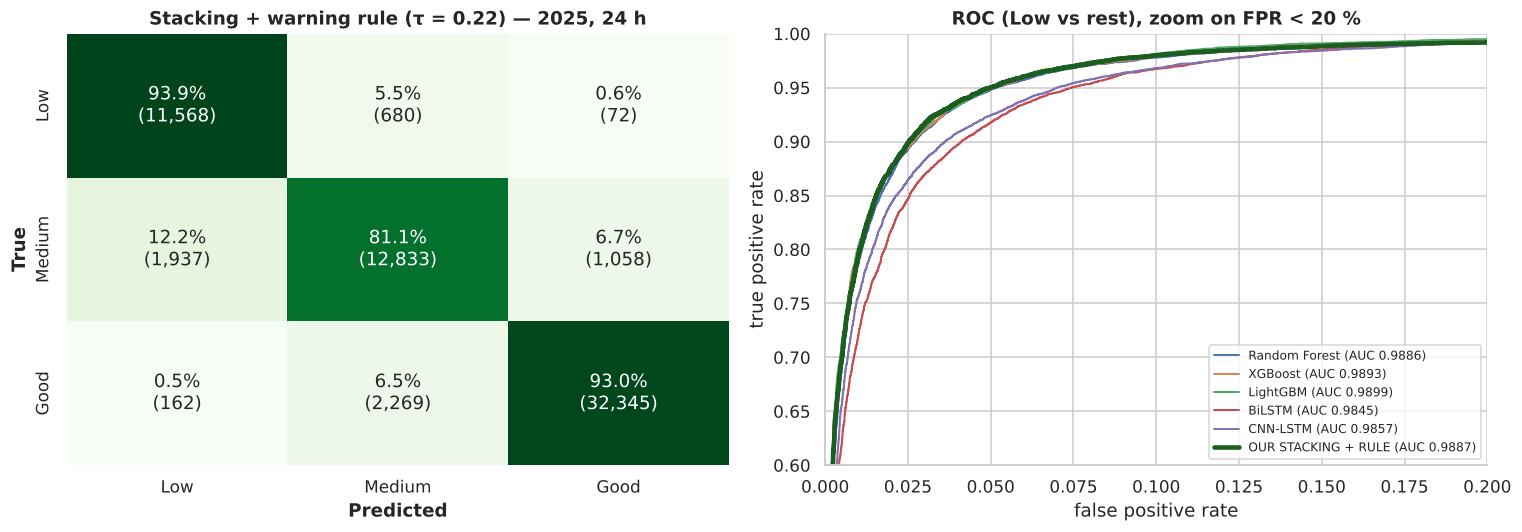

In [14]:
# @title 🧮 Confusion matrix & ROC curve of the proposed system
p = PRED["stacking"]["test_proba"]; pred = apply_rule(p, TAU); ok = ~np.isnan(yc) & ~np.isnan(p).any(1)
cm = confusion_matrix(yc[ok].astype(int), pred[ok], labels=[0, 1, 2]); pct = cm / cm.sum(1, keepdims=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pct, annot=np.array([[f"{a:.1f}%\n({b:,})" for a, b in zip(r1, r2)] for r1, r2 in zip(pct, cm)]), fmt="", cmap="Greens",
            cbar=False, ax=axes[0], xticklabels=CLASSES, yticklabels=CLASSES)
axes[0].set_xlabel("Predicted", fontweight="bold"); axes[0].set_ylabel("True", fontweight="bold")
axes[0].set_title(f"Stacking + warning rule (τ = {TAU:.2f}) — 2025, 24 h", fontweight="bold")
for m in MEMBERS + ["stacking"]:
    pp = PRED[m]["test_proba"]; k = ~np.isnan(yc) & ~np.isnan(pp).any(1)
    fpr, tpr, _ = roc_curve((yc[k] == 0).astype(int), pp[k, 0])
    axes[1].plot(fpr, tpr, lw=3 if m == "stacking" else 1.3, color="#1B5E20" if m == "stacking" else None,
                 label=f"{NICE[m]} (AUC {sk_auc(fpr, tpr):.4f})")
axes[1].plot([0, 1], [0, 1], "k:"); axes[1].set_xlim(0, .2); axes[1].set_ylim(.6, 1.0)
axes[1].set_title("ROC (Low vs rest), zoom on FPR < 20 %", fontweight="bold"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

## 10. Demo Run vs Full-Dataset Run
The demo pack uses one hour in four. The same pipeline trained on **every hour** (laptop RTX 3050, frozen settings, members
retrained on 2023 + 2024) produced the official 2025 results below. The ranking should be the same; the full run is a little
more accurate because it has four times more data (and 300 trees / 3 seeds).

,RMSE demo,RMSE full,macro F1 demo,macro F1 full,onset recall demo,onset recall full
model,,,,,,
Random Forest,0.7102,0.6924,0.8892,0.8928,0.2220,0.2505
XGBoost,0.7339,0.6951,0.8905,0.8934,0.2637,0.2992
LightGBM,0.6957,0.6822,0.8901,0.8936,0.2888,0.3245
BiLSTM,0.7054,0.6887,0.8649,0.8810,0.3591,0.3481
CNN-LSTM,0.7004,0.6860,0.8674,0.8804,0.3410,0.4217
OUR STACKING + RULE,0.6846,0.6718,0.8834,0.8860,0.4906,0.4958


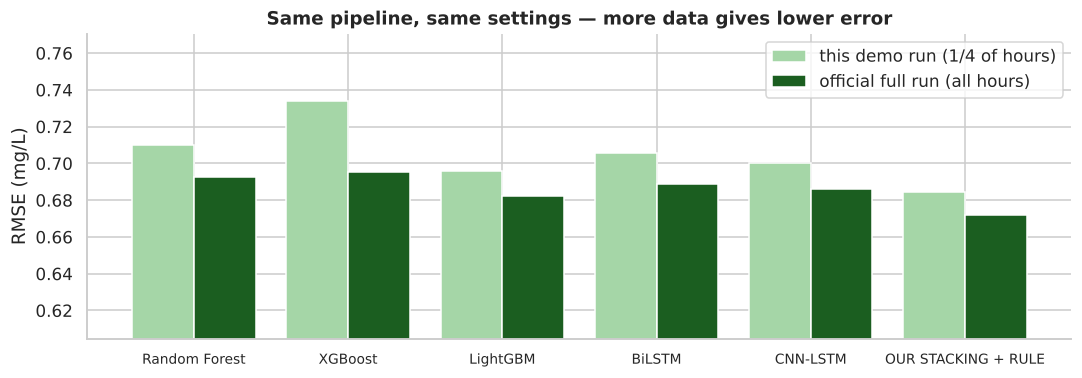

In [15]:
# @title 📊 This run vs the official full-dataset results (2025, 24 h)
FULL = json.loads(r'''{"random_forest":{"rmse":0.6924,"r2":0.9475,"f1":0.8928,"onset_recall":0.2505,"false_alarm":0.0039,"recall_low":0.9058},"xgboost":{"rmse":0.6951,"r2":0.9471,"f1":0.8934,"onset_recall":0.2992,"false_alarm":0.0053,"recall_low":0.9054},"lightgbm":{"rmse":0.6822,"r2":0.949,"f1":0.8936,"onset_recall":0.3245,"false_alarm":0.0059,"recall_low":0.9065},"bilstm":{"rmse":0.6887,"r2":0.948,"f1":0.881,"onset_recall":0.3481,"false_alarm":0.0093,"recall_low":0.895},"cnn_lstm":{"rmse":0.686,"r2":0.9484,"f1":0.8804,"onset_recall":0.4217,"false_alarm":0.013,"recall_low":0.9176},"stacking":{"rmse":0.6718,"r2":0.9505,"f1":0.886,"onset_recall":0.4958,"false_alarm":0.015,"recall_low":0.9409}}''')
cmp = []
for m in MEMBERS + ["stacking"]:
    me = LB.loc[NICE[m]]; f = FULL[m]
    cmp.append({"model": NICE[m], "RMSE demo": me["RMSE"], "RMSE full": f["rmse"], "macro F1 demo": me["macro_F1"], "macro F1 full": f["f1"],
                "onset recall demo": me["onset_recall"], "onset recall full": f["onset_recall"]})
display(pd.DataFrame(cmp).set_index("model").style.format("{:.4f}"))
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(6)
ax.bar(x - .2, [c["RMSE demo"] for c in cmp], .4, label="this demo run (1/4 of hours)", color="#A5D6A7")
ax.bar(x + .2, [c["RMSE full"] for c in cmp], .4, label="official full run (all hours)", color="#1B5E20")
ax.set_xticks(x); ax.set_xticklabels([c["model"] for c in cmp], fontsize=9); ax.set_ylabel("RMSE (mg/L)")
ax.set_ylim(min(c["RMSE full"] for c in cmp) * .9, max(c["RMSE demo"] for c in cmp) * 1.05); ax.legend()
ax.set_title("Same pipeline — more data gives lower error", fontweight="bold"); plt.tight_layout(); plt.show()

## 11. Real-Time Single-Hour Inference Demo
The trained models forecast one real 2025 hour that had not been seen by any of them.

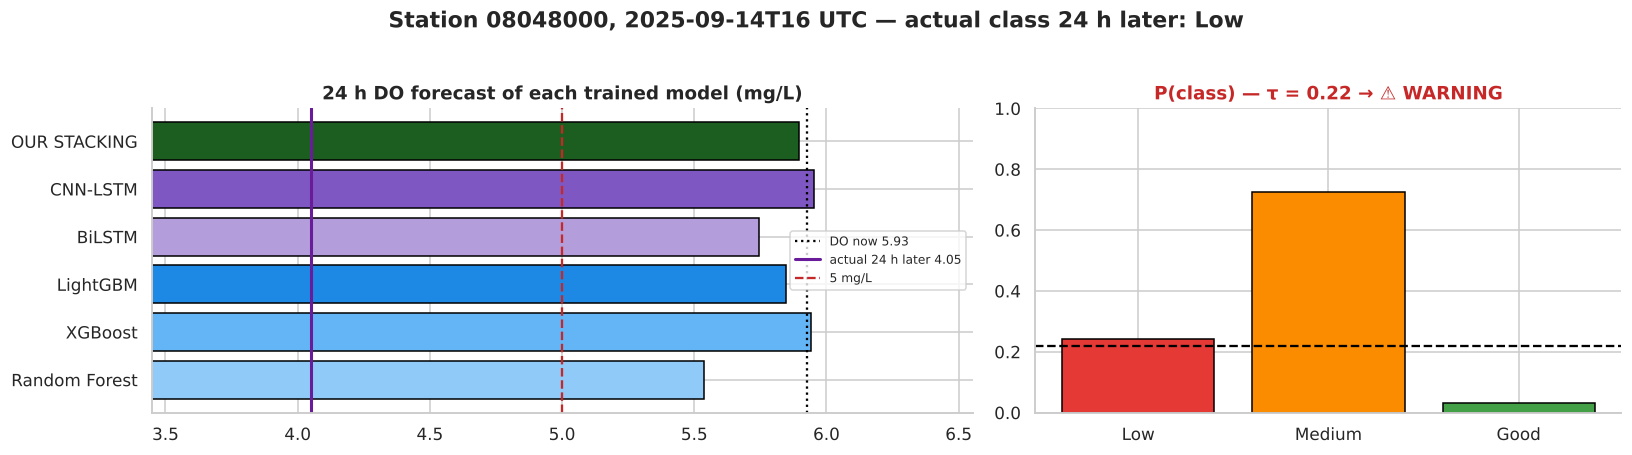

In [16]:
# @title 🩺 Forecast one unseen hour with all trained models
case = "safe now, Low in 24 h"  # @param ["safe now, Low in 24 h", "healthy river", "random hour"]
d = SPLITS["test"]; yr = d["y"][:, col[f"y_reg_{H}"]]; yc = d["y"][:, col[f"y_cls_{H}"]]
mask = {"safe now, Low in 24 h": (d["class_now"] != 0) & (yc == 0), "healthy river": (d["class_now"] == 2) & (yc == 2),
        "random hour": ~np.isnan(yc)}[case] & ~np.isnan(PRED["stacking"]["test_proba"]).any(1)
i = int(np.random.default_rng(7).choice(np.flatnonzero(mask)))
p = PRED["stacking"]["test_proba"][i]; warned = p[0] >= TAU
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.4, 1]})
vals = [PRED[m]["test_reg"][i] for m in MEMBERS] + [PRED["stacking"]["test_reg"][i]]
axes[0].barh([NICE[m] for m in MEMBERS] + ["OUR STACKING"], vals, color=["#90CAF9", "#64B5F6", "#1E88E5", "#B39DDB", "#7E57C2", "#1B5E20"], edgecolor="black")
axes[0].axvline(d["do_now"][i], color="black", ls=":", label=f"DO now {d['do_now'][i]:.2f}")
axes[0].axvline(yr[i], color="#6A1B9A", lw=2, label=f"actual 24 h later {yr[i]:.2f}"); axes[0].axvline(5, color="#C62828", ls="--", label="5 mg/L")
axes[0].set_xlim(min(vals + [yr[i], 5]) - .6, max(vals + [yr[i], d['do_now'][i]]) + .6); axes[0].legend(fontsize=8)
axes[0].set_title("24 h DO forecast of each trained model (mg/L)", fontweight="bold")
axes[1].bar(CLASSES, p, color=["#E53935", "#FB8C00", "#43A047"], edgecolor="black"); axes[1].axhline(TAU, color="black", ls="--")
axes[1].set_ylim(0, 1); axes[1].set_title(f"P(class) — τ = {TAU:.2f} → {'⚠️ WARNING' if warned else 'no warning'}", fontweight="bold",
                                          color="#C62828" if warned else "#2E7D32")
plt.suptitle(f"Station {STATIONS[d['station'][i]]}, {str(d['time'][i])} UTC — actual class 24 h later: {CLASSES[int(yc[i])]}",
             fontweight="bold", y=1.03); plt.tight_layout(); plt.show()

In [17]:
# @title ⏱️ Training-time summary
tt = pd.Series(TIMES) / 60
display(tt.rename("minutes").to_frame().style.format("{:.2f}"))
s = LB.loc[NICE["stacking"]]; b = LB.loc[NICE["lightgbm"]]
display(Markdown(f'''
**Total training time: {tt.sum():.1f} min on {device}.**
Proposed system on the unseen 2025 test hours of the demo pack: R² **{s["R2"]:.3f}**, RMSE **{s["RMSE"]:.3f} mg/L**,
accuracy **{s["accuracy"]:.3f}**, macro F1 **{s["macro_F1"]:.3f}**, Low recall **{s["Low_recall"]:.3f}**, onset recall
**{s["onset_recall"]:.3f}** at **{s["false_alarm"] * 100:.2f} %** false alarms (LightGBM alone: RMSE {b["RMSE"]:.3f}, onset recall {b["onset_recall"]:.3f}).
'''))

,minutes
Random Forest,2.06
XGBoost,3.71
LightGBM,0.74
BiLSTM,5.87
CNN-LSTM,1.61



**Total training time: 14.0 min on cpu.**
Proposed system on the unseen 2025 test hours of the demo pack: R² **0.949**, RMSE **0.685 mg/L**,
accuracy **0.902**, macro F1 **0.883**, Low recall **0.939**, onset recall
**0.491** at **1.61 %** false alarms (LightGBM alone: RMSE 0.696, onset recall 0.289).


---
# 🎓 What This Notebook Demonstrates (for the Review)

1. **A leakage-free pipeline** — chronological split with an automatic audit; every scaler, imputer and class weight fitted
   on 2023 only.
2. **Five genuinely different learners** — bagged trees, two boosting libraries, and two multi-task deep networks trained
   on the GPU with mixed precision and early stopping.
3. **A learned ensemble** — the stacking meta-learner, fitted on a year the base models never saw, gives the lowest error.
4. **A decision layer built for early warning** — τ chosen on 2024 under a false-alarm budget catches far more dangerous
   onsets than taking the most likely class.
5. **Honest scaling** — the same code on the full dataset produces the official results shown in Section 10.

*Full evaluation and comparison with existing algorithms: notebook 01 — Algorithm Comparison Benchmark.*